![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# Reference ET with the ASCE Standardized Penman-Monteith Equation

Reference evapotranspiration is the ET of an imaginary, well watered crop of fixed height and
surface resistance under the weather of the day. It captures the evaporative demand of the
atmosphere in one number. METRIC calibrates its cold anchor pixel against alfalfa reference ET
and scales every image to a day with it; SSEBop, SIMS and the seasonal accumulation in notebook
10 multiply by it as well. This notebook writes the ASCE standardized Penman-Monteith equation
term by term, checks it against the FAO-56 worked examples, computes hourly and daily reference
ET for 2024 from ERA5 weather, compares it with gridMET, and looks at the aridity problem of
weather recorded over dry land.

## Overview

### Two reference surfaces

| Reference | Symbol | Surface | Height | Surface resistance (day) |
|---|---|---|---|---|
| Short (grass) | ETo | clipped cool-season grass, FAO-56 | 0.12 m | 70 s/m daily, 50 s/m hourly |
| Tall (alfalfa) | ETr | full-cover alfalfa | 0.50 m | 45 s/m daily, 30 s/m hourly |

Alfalfa is taller, rougher and has more leaf area, so ETr is typically 15 to 40 % higher than
ETo, more in windy, dry weather. METRIC uses ETr because a full-cover, well watered crop in the image rarely
evaporates more than about 1.05 ETr, which makes it a natural ceiling for the cold anchor.

### The ASCE standardized equation

ASCE-EWRI (2005) fixed the Penman-Monteith equation for the two references into one form:

`ETsz = [0.408 Delta (Rn - G) + gamma Cn / (T + 273) u2 (es - ea)] / [Delta + gamma (1 + Cd u2)]`

| Symbol | Meaning | Unit |
|---|---|---|
| `Delta` | slope of the saturation vapour pressure curve at air temperature `T` | kPa/C |
| `Rn`, `G` | net radiation and soil heat flux of the reference surface | MJ m-2 per day or hour |
| `gamma` | psychrometric constant, `0.000665 P` | kPa/C |
| `u2` | wind speed at 2 m | m/s |
| `es - ea` | vapour pressure deficit (saturation minus actual) | kPa |
| `Cn`, `Cd` | constants for the reference and time step (table below) | |
| `0.408` | `1 / lambda` in kg/MJ | |

| Time step | Reference | Cn | Cd | G |
|---|---|---|---|---|
| daily | short | 900 | 0.34 | 0 |
| daily | tall | 1600 | 0.38 | 0 |
| hourly, day | short | 37 | 0.24 | 0.1 Rn |
| hourly, day | tall | 66 | 0.25 | 0.04 Rn |
| hourly, night | short | 37 | 0.96 | 0.5 Rn |
| hourly, night | tall | 66 | 1.7 | 0.2 Rn |

The numerator has a **radiation term** (energy available) and an **aerodynamic term** (the
drying power of warm, dry, moving air). Net radiation of the reference surface uses albedo 0.23,
`Rns = 0.77 Rs`, and the net longwave `Rnl = sigma T^4 (0.34 - 0.14 sqrt(ea)) (1.35 Rs/Rso -
0.35)`, where `Rso` is clear-sky radiation from extraterrestrial radiation `Ra` and elevation.
FAO-56 is the daily short reference of this equation; its hourly form uses `Cd = 0.34` both day
and night.

### Weather over irrigated land and over dry land

The equation assumes the weather was measured over a well watered reference. A station or
reanalysis grid cell over dry land records hotter, drier air, and the equation then overstates
the demand of an irrigated field (Allen 1996; Temesgen et al. 1999). A common diagnostic is the
difference between the daily minimum air temperature and the dew point: over a well watered
surface the air is near saturation at dawn, so `Tmin - Tdew` is usually below 2 to 3 C. Larger
differences point to arid conditions, and FAO-56 (Annex 6) suggests raising the dew point to
`Tmin - K0` with `K0` of about 2 C before computing reference ET. ERA5 and gridMET grid cells
mix irrigated fields with dry rangeland and foothills, so they carry some of this aridity.

## Reference ET with GeoLattice

| Function | Purpose |
|---|---|
| `seb.asce_pm_daily(tmax, tmin, ea, rs, u2, z, lat, doy, reference=)` | daily ETo or ETr (mm/d) |
| `seb.asce_pm_hourly(t, ea, rs, u2, z, lat, lon, when, reference=)` | hourly ETo or ETr (mm/h) at a UTC time |
| `seb.fao56_eto` | the FAO-56 daily grass reference |
| `seb.extraterrestrial_radiation_daily`, `_hourly` | `Ra` for clear-sky radiation |
| `seb.saturation_vapour_pressure`, `seb.slope_vapour_pressure_curve`, `seb.psychrometric_constant` | the thermodynamic terms |
| `seb.wind_2m` | wind from any height to 2 m |
| `sd.daily_reference`, `sd.gridmet_point` | daily ERA5 reference ET and gridMET for the site |

### Learning objectives

1. Explain the grass and alfalfa references and why METRIC uses alfalfa.
2. Write the ASCE standardized equation and the meaning and units of every term.
3. Reproduce the FAO-56 daily and hourly worked examples.
4. Split a day's reference ET into its radiation and aerodynamic parts.
5. Compute hourly reference ET at the Landsat overpass and daily reference ET for a whole year.
6. Compare ERA5 and gridMET reference ET and explain their differences.
7. Diagnose aridity in gridded weather and estimate its effect.

### Data

| Dataset | Content |
|---|---|
| ERA5 daily and hourly (Open-Meteo archive) | 2024 at 36.425 N, 120.10 W: maximum and minimum temperature, dew point, shortwave, wind at 10 m |
| gridMET daily (Climatology Lab THREDDS) | 2024 at the same point, 4 km: ETr, ETo, temperature, specific humidity, shortwave, wind |

### Contents

- Setup
- Checking the equation with the FAO-56 examples
- One day term by term
- Hourly reference ET and the overpass
- A year of daily reference ET
- ERA5 and gridMET
- Aridity of the weather data
- Saving the daily series
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

SITE = sd.WESTSIDE  # Westside San Joaquin Valley
Z = 65.0  # elevation of the weather point, m (median of the window is 66 m)

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## Checking the equation with the FAO-56 examples

FAO-56 (Allen et al. 1998) works two examples by hand. Example 18 is a daily ETo for Brussels on
6 July (expected 3.9 mm/d), and example 19 an hourly ETo for N'Diaye, Senegal, on 1 October from
14:00 to 15:00 (expected 0.63 mm/h, with the FAO hourly `Cd = 0.34` and `G = 0.1 Rn`). The
Senegal hour is centred on 15:30 UTC in this convention.

In [2]:
ex18 = seb.fao56_eto(21.5, 12.3, 1.409, 22.07, seb.wind_2m(10 / 3.6, 10), 100, 50.8, 187)  # Brussels, 6 July
ea19 = seb.actual_vapour_pressure(t_c=38.0, rh=52.0)  # N'Diaye: 38 C, 52 % humidity
ex19 = seb.asce_pm_hourly(38.0, ea19, 2.450, 3.3, 8, 16.217, -16.25, "2026-10-01 15:30", cd=0.34, g_ratio=0.1)  # 14:00 to 15:00
pd.DataFrame({"FAO-56 result": [3.9, 0.63], "seb": [round(float(ex18), 2), round(float(ex19), 3)]},
             index=["Example 18, daily ETo (mm/d)", "Example 19, hourly ETo (mm/h)"])  # comparison

,FAO-56 result,seb
"Example 18, daily ETo (mm/d)",3.90,3.880
"Example 19, hourly ETo (mm/h)",0.63,0.627


Both match the published results to the precision FAO-56 reports.

## One day term by term

5 July 2024, the day of the main Landsat scene, was in a heat wave. The ERA5 daily values at the
site go into the equation step by step, so each term can be read off.

In [3]:
d = sd.weather(SITE, "2024-01-01", "2024-12-31")["daily"]  # ERA5 daily for 2024 (cached)
day = d.loc["2024-07-05"]  # the overpass day
tmax, tmin, rs = day.temperature_2m_max, day.temperature_2m_min, day.shortwave_radiation_sum  # C, C, MJ m-2
ea = float(seb.actual_vapour_pressure(t_dew_c=day.dew_point_2m_mean))  # kPa from the mean dew point
u2 = float(seb.wind_2m(day.wind_speed_10m_mean, 10))  # m/s at 2 m
t = (tmax + tmin) / 2  # mean air temperature
P = float(seb.pressure_from_elevation(Z)); gamma = seb.psychrometric_constant(P)  # kPa and kPa/C
delta = float(seb.slope_vapour_pressure_curve(t))  # kPa/C
es = (seb.saturation_vapour_pressure(tmax) + seb.saturation_vapour_pressure(tmin)) / 2  # mean saturation pressure
ra = float(seb.extraterrestrial_radiation_daily(SITE["lat"], 187)); rso = (0.75 + 2e-5 * Z) * ra  # MJ m-2 d-1
rnl = 4.901e-9 * ((tmax + 273.16) ** 4 + (tmin + 273.16) ** 4) / 2 * (0.34 - 0.14 * ea ** 0.5) * (1.35 * min(rs / rso, 1) - 0.35)  # net longwave
rn = 0.77 * rs - rnl  # net radiation of the reference surface
rows = {}  # term table
for ref, cn, cd in [("ETo (grass)", 900, 0.34), ("ETr (alfalfa)", 1600, 0.38)]:  # both references
    den = delta + gamma * (1 + cd * u2)  # denominator
    rad = 0.408 * delta * rn / den  # radiation term, mm/d
    aero = gamma * cn / (t + 273) * u2 * (es - ea) / den  # aerodynamic term, mm/d
    rows[ref] = {"radiation term": rad, "aerodynamic term": aero, "total": rad + aero,
                 "seb.asce_pm_daily": float(seb.asce_pm_daily(tmax, tmin, ea, rs, u2, Z, SITE["lat"], 187,
                                                                reference="tall" if cd == 0.38 else "short"))}  # check
print(f"Tmax {tmax} C, Tmin {tmin} C, Tdew {day.dew_point_2m_mean} C, ea {ea:.2f} kPa, es - ea {es - ea:.2f} kPa, "
      f"u2 {u2:.2f} m/s, Rs {rs} MJ m-2 (Rso {rso:.1f}), Rn {rn:.1f} MJ m-2")  # inputs
pd.DataFrame(rows).T.round(2)  # mm/d

Tmax 46.6 C, Tmin 25.6 C, Tdew 4.2 C, ea 0.82 kPa, es - ea 6.02 kPa, u2 2.56 m/s, Rs 29.65 MJ m-2 (Rso 31.1), Rn 13.8 MJ m-2


,radiation term,aerodynamic term,total,seb.asce_pm_daily
ETo (grass),4.08,6.62,10.70,10.70
ETr (alfalfa),4.02,11.59,15.61,15.61


On this hot, very dry day the aerodynamic term contributes more than the radiation term to both
references, and more so for alfalfa, whose larger `Cn` reflects its rougher surface. The hand
computation equals `seb.asce_pm_daily`. Net radiation of the reference surface (13.8 MJ m-2) is
less than half of the incoming shortwave (29.7 MJ m-2): after the 23 % reflected, the hot surface
and the dry, clear sky make the net longwave loss large.

## Hourly reference ET and the overpass

METRIC needs ETr at the moment of the image (to calibrate the cold anchor) and for the whole
day (to scale the image). The hourly equation runs on each ERA5 hour; ERA5 hours are averages
ending at the time stamp, so the centre of each hour is 30 minutes earlier.

sum of 24 hourly ETr 12.9 mm, daily equation 15.6 mm | sum of hourly ETo 9.7 mm, daily 10.7 mm
ETr at the overpass (18:33 UTC): 0.93 mm/h


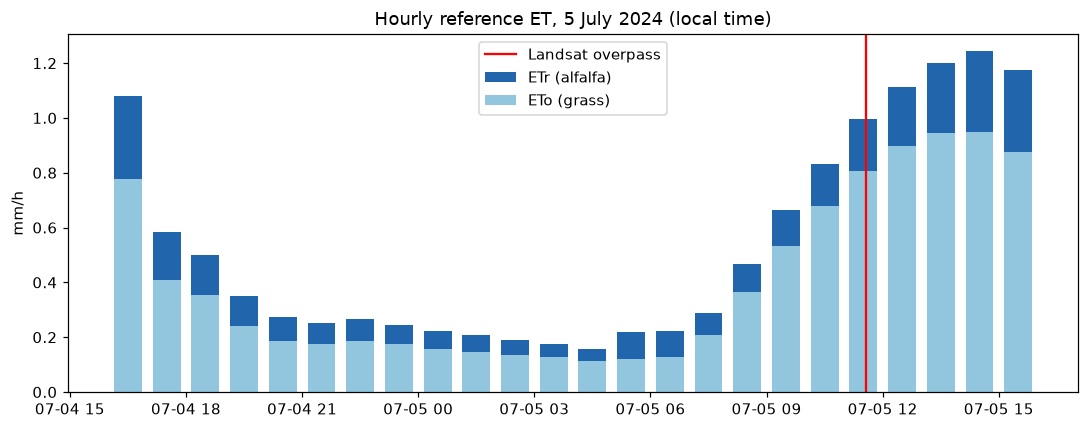

In [4]:
h = sd.weather(SITE, "2024-07-05", "2024-07-05")["hourly"]  # ERA5 hourly, UTC
mid = h.index - pd.Timedelta(minutes=30)  # centre of each hour
ea_h = seb.actual_vapour_pressure(t_dew_c=h.dew_point_2m.values)  # kPa
u2_h = seb.wind_2m(h.wind_speed_10m.values, 10)  # m/s
etr_h = np.array([float(seb.asce_pm_hourly(T, e, r * 0.0036, u, Z, SITE["lat"], SITE["lon"], m, reference="tall"))
                  for T, e, r, u, m in zip(h.temperature_2m, ea_h, h.shortwave_radiation, u2_h, mid)])  # mm/h
eto_h = np.array([float(seb.asce_pm_hourly(T, e, r * 0.0036, u, Z, SITE["lat"], SITE["lon"], m, reference="short"))
                  for T, e, r, u, m in zip(h.temperature_2m, ea_h, h.shortwave_radiation, u2_h, mid)])  # mm/h
scene = sd.load_scene(sd.MAIN_SCENE)  # the overpass time is in the scene attributes
ref = sd.reference_et(scene)  # overpass ETr and daily ETr used by the later notebooks
print(f"sum of 24 hourly ETr {etr_h.sum():.1f} mm, daily equation {rows['ETr (alfalfa)']['total']:.1f} mm | "
      f"sum of hourly ETo {eto_h.sum():.1f} mm, daily {rows['ETo (grass)']['total']:.1f} mm")  # hourly vs daily
print(f"ETr at the overpass ({pd.Timestamp(scene.attrs['datetime']):%H:%M} UTC): {ref['etr_inst']:.2f} mm/h")  # instant value

fig, ax = plt.subplots(figsize=(10, 4))  # one panel
local = mid + pd.Timedelta(hours=SITE["utc_offset"])  # local time
ax.bar(local, etr_h, width=0.03, color="#2166ac", label="ETr (alfalfa)")  # hourly ETr
ax.bar(local, eto_h, width=0.03, color="#92c5de", label="ETo (grass)")  # hourly ETo in front
ax.axvline(pd.Timestamp(scene.attrs["datetime"]) + pd.Timedelta(hours=SITE["utc_offset"]), color="r", label="Landsat overpass")  # image time
ax.set_ylabel("mm/h"); ax.legend(); ax.set_title("Hourly reference ET, 5 July 2024 (local time)")  # labels
plt.tight_layout(); plt.show()  # draw

The 24 hourly values add up to less than the daily equation gives on this day (12.9 against 15.6
mm for alfalfa). The daily form averages the saturation vapour pressure at Tmax and Tmin, which on
a day with a 21 C range overstates the mean deficit because saturation pressure rises steeply
with temperature, and it applies daytime constants to the whole day's mean wind; at night the
hourly form uses a much larger `Cd` and so little ET. ASCE (2005) prefers the sum of hourly
values when hourly data exist, while many METRIC applications use the daily form. The chapter uses ERA5 for
both the overpass ETr and the daily ETr, so every image is scaled with the same weather source.

## A year of daily reference ET

`sd.daily_reference` applies the daily equation to every ERA5 day of 2024 (the same steps as
above, vectorized).

2024 totals: ETr 2366 mm, ETo 1706 mm (Open-Meteo's own ETo 1709 mm), rain 320 mm
April to October: ETr 1979 mm, ratio ETr/ETo 1.39


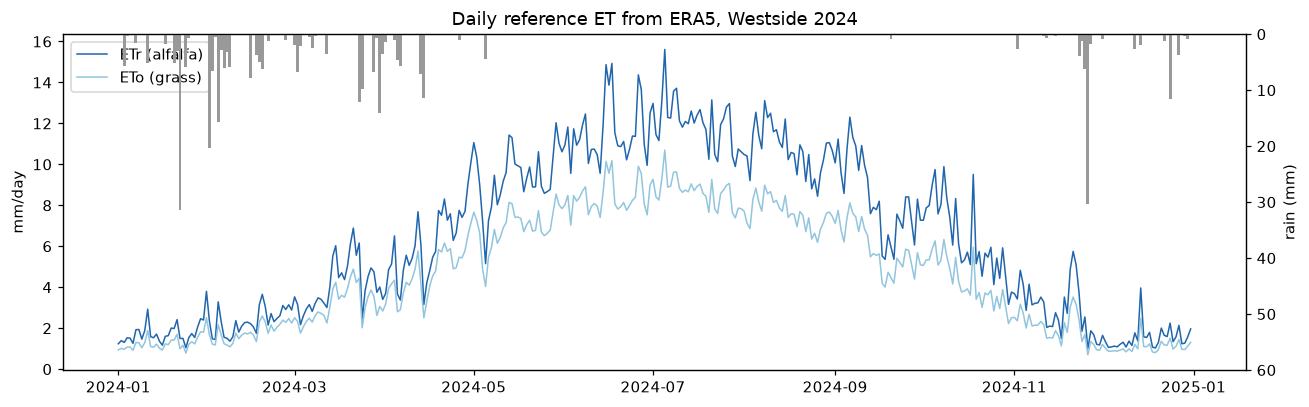

In [5]:
era = sd.daily_reference(SITE, "2024-01-01", "2024-12-31", z=Z)  # ETr, ETo, Open-Meteo's ETo, rain
print(f"2024 totals: ETr {era.etr.sum():.0f} mm, ETo {era.eto.sum():.0f} mm (Open-Meteo's own ETo {era.eto_openmeteo.sum():.0f} mm), "
      f"rain {era.precip.sum():.0f} mm")  # annual totals
print(f"April to October: ETr {era.loc['2024-04':'2024-10'].etr.sum():.0f} mm, ratio ETr/ETo {(era.etr / era.eto).loc['2024-04':'2024-10'].mean():.2f}")  # season
fig, ax = plt.subplots(figsize=(12, 3.8))  # one panel
ax.plot(era.etr, color="#2166ac", lw=1, label="ETr (alfalfa)")  # daily ETr
ax.plot(era.eto, color="#92c5de", lw=1, label="ETo (grass)")  # daily ETo
ax2 = ax.twinx(); ax2.bar(era.index, era.precip, color="#999999", width=1); ax2.set_ylim(60, 0); ax2.set_ylabel("rain (mm)")  # rain from the top
ax.set_ylabel("mm/day"); ax.legend(loc="upper left"); ax.set_title("Daily reference ET from ERA5, Westside 2024")  # labels
plt.tight_layout(); plt.show()  # draw

Reference ET follows the sun and the heat: about 1 to 2 mm/d in winter and over 10 mm/d (ETr) in
summer, with the early July heat wave standing out. The 320 mm of rain in the ERA5 cell, nearly
all between November and April, is a small fraction of the 2,366 mm alfalfa reference demand, so
crops on the Westside depend on irrigation. In the irrigation season (April to October) ETr is
on average 1.39 times ETo. Open-Meteo's own grass ETo is computed from hourly
values and differs a little from the daily equation used here.

## ERA5 and gridMET

gridMET (Abatzoglou 2013) combines PRISM and NLDAS-2 at 4 km and publishes daily ETr and ETo with
the ASCE equation. It is the weather behind OpenET. The two products agree on the seasonal cycle
but differ day by day.

ERA5 compared with gridMET (gridMET as the reference):


,n,mean_obs,mean_pred,bias,rmse,r2
ETr,366.0,6.64,6.46,-0.18,1.17,0.93
ETo,366.0,4.78,4.66,-0.12,0.69,0.95


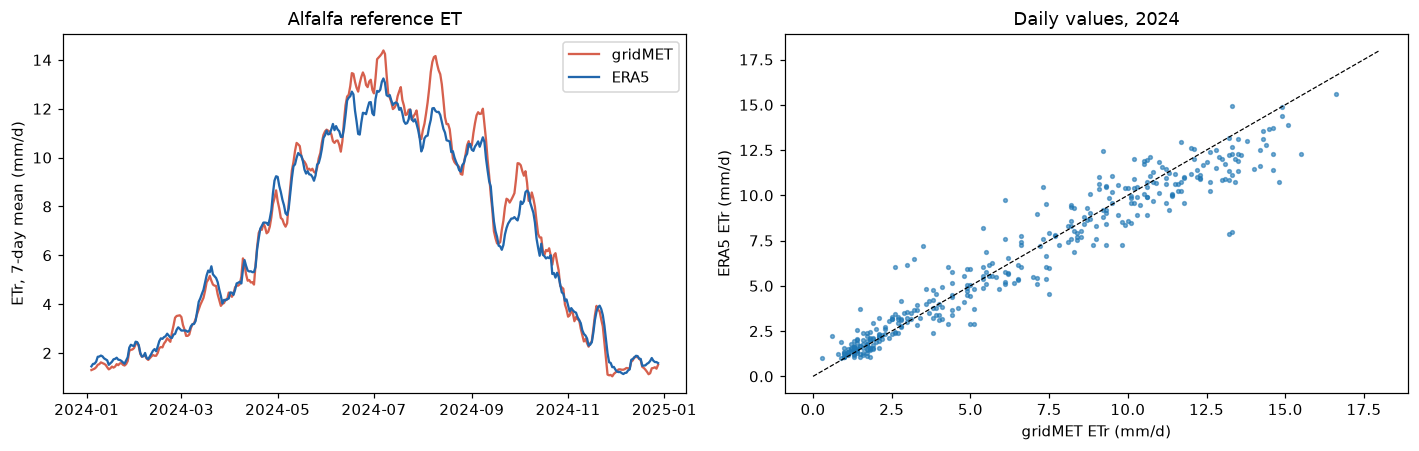

In [6]:
gm = sd.gridmet_point(SITE, "2024-01-01", "2024-12-31")  # gridMET daily (cached)
both = pd.DataFrame({"ERA5 ETr": era.etr, "gridMET ETr": gm.etr, "ERA5 ETo": era.eto, "gridMET ETo": gm.pet}).dropna()  # aligned days
stats = pd.DataFrame({"ETr": seb.compare_to_tower(both["ERA5 ETr"], both["gridMET ETr"]),  # ERA5 against gridMET
                      "ETo": seb.compare_to_tower(both["ERA5 ETo"], both["gridMET ETo"])}).T  # both references
print("ERA5 compared with gridMET (gridMET as the reference):")  # what the table shows
display(stats[["n", "mean_obs", "mean_pred", "bias", "rmse", "r2"]].round(2))  # agreement
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))  # two panels
ax[0].plot(both["gridMET ETr"].rolling(7, center=True).mean(), label="gridMET", color="#d6604d")  # weekly mean gridMET
ax[0].plot(both["ERA5 ETr"].rolling(7, center=True).mean(), label="ERA5", color="#2166ac")  # weekly mean ERA5
ax[0].set_ylabel("ETr, 7-day mean (mm/d)"); ax[0].legend(); ax[0].set_title("Alfalfa reference ET")  # labels
ax[1].scatter(both["gridMET ETr"], both["ERA5 ETr"], s=6, alpha=0.6); ax[1].plot([0, 18], [0, 18], "k--", lw=0.8)  # daily scatter
ax[1].set_xlabel("gridMET ETr (mm/d)"); ax[1].set_ylabel("ERA5 ETr (mm/d)"); ax[1].set_title("Daily values, 2024")  # labels
plt.tight_layout(); plt.show()  # draw

In [7]:
p_kpa = float(seb.pressure_from_elevation(Z))  # station pressure for humidity
gm_ea = gm.sph * p_kpa / (0.622 + 0.378 * gm.sph)  # gridMET vapour pressure from specific humidity, kPa
inputs = pd.DataFrame({  # summer means of the driving variables
    "Tmax (C)": [d.temperature_2m_max, gm.tmmx - 273.15], "Tmin (C)": [d.temperature_2m_min, gm.tmmn - 273.15],
    "vapour pressure (kPa)": [pd.Series(seb.actual_vapour_pressure(t_dew_c=d.dew_point_2m_mean.values), d.index), gm_ea],
    "shortwave (MJ/m2/d)": [d.shortwave_radiation_sum, gm.srad * 0.0864], "wind at 10 m (m/s)": [d.wind_speed_10m_mean, gm.vs]},
    index=["ERA5", "gridMET"])  # each cell is a daily series
inputs.map(lambda s: s.loc["2024-06":"2024-08"].mean()).round(2)  # June to August means

,Tmax (C),Tmin (C),vapour pressure (kPa),shortwave (MJ/m2/d),wind at 10 m (m/s)
ERA5,41.64,21.75,0.97,27.87,2.58
gridMET,38.23,18.75,1.20,29.34,3.49


Over the whole year ERA5 ETr is 0.18 mm/d lower than gridMET on average (RMSE 1.17 mm/d, R2
0.93). The inputs show why the difference is small despite large disagreements: in summer ERA5 is
about 3 C hotter and drier (0.97 against 1.20 kPa vapour pressure), which raises its ETr, but its
wind is about 0.9 m/s weaker, which lowers it, and the two partly cancel. Neither
is "the truth"; a station on irrigated grass (such as CIMIS station 2, Five Points, which needs a
free key) would be the reference to check both against.

## Aridity of the weather data

Over a well watered surface the dew point at dawn is close to the minimum temperature. The
distribution of `Tmin - Tdew` in summer shows how far the gridded weather is from that state, and
the FAO-56 adjustment (`Tdew` raised to at least `Tmin - 2` C) shows what it would change.

In [8]:
summer = d.loc["2024-05":"2024-09"]  # dry season
gap = summer.temperature_2m_min - summer.dew_point_2m_mean  # Tmin - Tdew, C
print(f"ERA5 May to September: Tmin - Tdew median {gap.median():.1f} C, 90th percentile {gap.quantile(0.9):.1f} C")  # aridity diagnostic
tdew_adj = np.maximum(d.dew_point_2m_mean, d.temperature_2m_min - 2.0)  # FAO-56 Annex 6 adjustment, K0 = 2 C
ea_adj = seb.actual_vapour_pressure(t_dew_c=tdew_adj.values)  # adjusted vapour pressure
etr_adj = seb.asce_pm_daily(d.temperature_2m_max.values, d.temperature_2m_min.values, ea_adj, d.shortwave_radiation_sum.values,
                            seb.wind_2m(d.wind_speed_10m_mean.values, 10), Z, SITE["lat"], d.index.dayofyear.values, reference="tall")  # ETr with adjusted humidity
adj = pd.Series(etr_adj, index=d.index)  # as a series
season = slice("2024-04", "2024-10")  # irrigation season
print(f"April to October ETr: {era.etr.loc[season].sum():.0f} mm as measured, {adj.loc[season].sum():.0f} mm with the humidity adjustment "
      f"({100 * (adj.loc[season].sum() / era.etr.loc[season].sum() - 1):.0f} %)")  # effect on the season

ERA5 May to September: Tmin - Tdew median 13.0 C, 90th percentile 20.0 C
April to October ETr: 1979 mm as measured, 1742 mm with the humidity adjustment (-12 %)


A median `Tmin - Tdew` of 13 C, far above 2 C, says the ERA5 air at this point is much drier
than air over an irrigated field. Raising the dew point lowers the season's ETr by 12 % (1,979 to
1,742 mm). This
is an upper bound of the effect: the adjustment assumes a fully irrigated landscape, while the
Westside is a mix of irrigated and fallow land. Studies that need absolute accuracy correct
gridded weather against local agricultural stations (OpenET bias-corrects gridMET ETo and ETr
with station ratios). For METRIC the absolute level matters less than consistency: the cold anchor
is calibrated to 1.05 ETr and the image is scaled with ETr from the same source, so a constant bias
largely cancels in the fraction and returns only through the daily scaling.

## Saving the daily series

Notebooks 10 to 12 read the daily reference ET of 2024 from this file.

In [9]:
out = era.assign(etr_gridmet=gm.etr, eto_gridmet=gm.pet, etr_humidity_adjusted=adj)  # all series together
out.to_csv(OUT / "reference_et_westside_2024.csv")  # saved table
print(OUT / "reference_et_westside_2024.csv", out.shape)  # path and size
out.loc["2024-07-01":"2024-07-08"].round(2)  # the heat wave week

outputs/reference_et_westside_2024.csv (366, 7)


,etr,eto,eto_openmeteo,precip,etr_gridmet,eto_gridmet,etr_humidity_adjusted
time,,,,,,,
2024-07-01,12.98,9.27,9.10,0.0,13.8,9.9,10.96
2024-07-02,11.45,8.41,8.25,0.0,14.0,10.0,10.29
2024-07-03,11.16,8.25,8.13,0.0,12.0,8.9,10.32
2024-07-04,13.09,9.30,9.03,0.0,13.5,9.7,11.50
2024-07-05,15.61,10.70,10.41,0.0,16.6,11.4,12.97
2024-07-06,12.29,8.89,8.64,0.0,15.5,10.9,11.29
2024-07-07,12.27,8.94,8.73,0.0,13.3,9.7,11.19
2024-07-08,13.57,9.62,9.27,0.0,14.3,10.2,12.26


## Summary and exercises

- The ASCE standardized equation gives grass (ETo) and alfalfa (ETr) reference ET from
  temperature, humidity, radiation and wind; `seb.fao56_eto` and `seb.asce_pm_hourly` reproduce
  the FAO-56 examples 18 (3.9 mm/d) and 19 (0.63 mm/h).
- On 5 July 2024, a hot, very dry day, the aerodynamic term contributed more than the radiation
  term, and ETr exceeded 15 mm.
- On 5 July the 24 hourly values summed to 12.9 mm against 15.6 mm from the daily equation;
  the daily form overstates the deficit on days with a large temperature range.
- ERA5 and gridMET agree on the seasonal cycle (R2 0.93 for daily ETr) but ERA5 is hotter, drier
  and less windy, effects that partly cancel.
- Gridded weather over a mix of irrigated and dry land is drier than air over an irrigated
  field (median `Tmin - Tdew` of 13 C in ERA5); the FAO-56 dew point adjustment would lower the
  season's ETr by up to 12 %.

**Exercises**

1. Recompute the 5 July term table with gridMET inputs. Which input changes the aerodynamic
   term the most?
2. Use `seb.asce_pm_hourly` with `reference="short"` for every hour of July 2024 and compare the
   monthly sum with the daily equation's sum. In which weather is the difference largest?
3. Repeat the aridity adjustment with `K0 = 0`, 2 and 4 C. How sensitive is the season's ETr?
4. Compute the ETr/ETo ratio for every day of 2024 and plot it against wind speed. Why does it
   rise with wind?